# Entrega 2 — Anticipar qué reclamos urbanos se resuelven en una semana

Machine Learning · Grupos de 4 · 10 % de la calificación final · Vence el jueves 5 de noviembre

**Integrantes**

1. Marcos Devincenzi
2. Santiago Alba
3. Facundo Díaz
4. Domingo Leiva

---

La consigna completa está en `entrega_reclamos_im.pdf`. Este notebook fija las ocho secciones y su orden; la corrección se hace contra el enunciado, no contra el template.

Condiciones de uso:

- Las celdas de texto describen qué se pide en cada sección y no se eliminan. Las respuestas escritas se agregan en las celdas marcadas para eso, que pueden extenderse tanto como haga falta.
- Las celdas de código llegan vacías y pueden dividirse en tantas como convenga.
- El notebook se entrega ejecutado de punta a punta, con todas las salidas visibles y en el orden en que se generaron. Un notebook sin ejecutar no está entregado.
- Toda celda con aleatoriedad fija su semilla, y la semilla se mantiene igual en todas las comparaciones del notebook: dos resultados que se comparan no pueden diferir por la partición.

Los datos son el archivo abierto de la Intendencia de Montevideo «Reclamos registrados en el Sistema Único de Reclamos», que se descarga de <https://catalogodatos.gub.uy/dataset/reclamos-registrados-en-el-sistema-unico-de-reclamos-de-la-intendencia-de-montevideo>. Es un ZIP de unos 44 MB que descomprime a un CSV de unos 305 MB.

- Ventana de trabajo: reclamos ingresados entre 2017 y 2019, inclusive.
- Conjunto de prueba: los ingresados en 2019. Se apartan antes de cualquier ajuste y solo se usan en las secciones 7 y 8.

La ruta del archivo descargado y su fecha de descarga se declaran en la celda de configuración de abajo y en ningún otro lado, de modo que el notebook pueda reproducirse cambiando una sola línea. En Colab, el archivo debe subirse o montarse antes de la primera lectura.

### Configuración: importaciones, rutas, fecha de descarga y semilla

Importar las bibliotecas que el trabajo use, declarar la ruta del archivo y su fecha de descarga, y fijar la semilla. Nada de esta celda se evalúa.

In [1]:
import os, json, zipfile, hashlib, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import roc_auc_score, average_precision_score, silhouette_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.inspection import permutation_importance
from IPython.display import display, Markdown

ARCHIVO = Path('data/reclamos.csv')
ZIP_ORIGINAL = Path('data/reclamos.zip')
METADATOS = Path('data/metadata.txt')
MANIFIESTO = Path('data/fuentes.json')
FECHA_DESCARGA = json.loads(MANIFIESTO.read_text(encoding='utf-8'))['fecha_descarga']
SEMILLA = 42
np.random.seed(SEMILLA)
SALIDA = Path('resultados'); SALIDA.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize':(9,4),'axes.grid':True,'grid.alpha':.2})
pd.set_option('display.max_colwidth',90)
RES = {}
def guardar(nombre, tabla):
    tabla.to_csv(SALIDA/(nombre+'.csv'),index=False);display(tabla)
def mostrar(texto): display(Markdown(texto))
def metricas(y,p): return {'AUC':roc_auc_score(y,p),'AP':average_precision_score(y,p)}
def reloj_fit_predict(modelo,Xa,ya,Xv):
    t=time.perf_counter();modelo.fit(Xa,ya);ajuste=time.perf_counter()-t
    t=time.perf_counter()
    p=modelo.predict_proba(Xv)[:,1] if hasattr(modelo,'predict_proba') else modelo.decision_function(Xv)
    return p,ajuste,time.perf_counter()-t
print('Fecha de descarga:',FECHA_DESCARGA)


Fecha de descarga: 2026-10-22T12:15:38.015579-03:00


## 1. Datos, respuesta y población

Documentar la ingesta —cuántas filas trae el archivo, cuántas caen en la ventana de trabajo y cuántas en cada año— y caracterizar el conjunto antes de ajustar ningún modelo: tipos, distribución de cada variable, filas repetidas, valores imposibles, cardinalidad de las variables categóricas y cómo se distribuyen los estados del reclamo según el año de ingreso. Contrastar el archivo con la descripción de campos publicada.

Construir después la respuesta —el reclamo se resuelve en 7 días corridos o menos desde su ingreso— y declarar la población sobre la que se modela: qué reclamos se excluyen, cuántos son y qué sesgo introduce cada exclusión. Declarar también qué columnas quedan fuera de la matriz de entrada y por qué, una por una.

Por último, apartar 2019 y elegir el esquema de validación con el que se van a tomar todas las decisiones sobre 2017–2018. La elección se justifica por cómo se va a usar el modelo.

Un hallazgo sin la cifra o el gráfico que lo produce no cuenta como hallazgo.

> Esta sección se apoya en validación temporal, que se dicta más adelante en el curso.

Original: (1709419, 15) fechas de ingreso inválidas: 0
Descripción de campos 
---------------------
NUMERO_RECLAMO:		Es el número con el que el reclamo está registrado en el SUR. Lo genera el sistema.
FECHA_INGRESO_RECLAMO: 	Fecha en que el reclamo se dio de alta en el sistema.
CODIGO_ESTADO:         	Código del estado en que se encuentra actualmente el reclamo.
DESC_ESTADO:	 	Descripción del estado en que se encuentra actualmente el reclamo.
FECHA_DESDE_EN_ESTADO:  Fecha en que el reclamo pasó al estado actual.
CODIGO_AREA: 		Código del área de la IM que gestiona el reclamo.
DESC_AREA:              Descripción del área de la IM que gestiona el reclamo.
CODIGO_GRUPO: 		Código del grupo al que pertenece el reclamo.
DESC_GRUPO:             Descripción del grupo al que pertenece el reclamo.
CODIGO_TIPOPROBLEMA: 	Código del tipo de problema asociado al reclamo.
DESC_TIPOPROBLEMA:      Descripción del tipo de problema asociado al reclamo.
COORD_X: 		Coordenada X de la ubicación del reclamo 

,anio,reclamos
0,2017,130178
1,2018,125227
2,2019,140238


DESC_ESTADO,anio,Anulado,En Proceso,Finalizado,Ingresado
0,2017,4781,245,125144,8
1,2018,4404,917,119791,115
2,2019,5468,1254,133216,300


,columna,tipo,faltantes,cardinalidad
0,NUMERO_RECLAMO,int64,0,1709106
1,FECHA_INGRESO_RECLAMO,str,0,5736
2,CODIGO_ESTADO,int64,0,4
3,DESC_ESTADO,str,0,4
4,FECHA_DESDE_EN_ESTADO,str,0,5422
5,CODIGO_AREA,int64,0,13
6,DESC_AREA,str,0,13
7,CODIGO_GRUPO,int64,0,60
8,DESC_GRUPO,str,0,60
9,CODIGO_TIPOPROBLEMA,int64,0,256


             LATITUD       LONGITUD
count  395643.000000  395643.000000
mean      -34.868210     -56.170892
std         0.032412       0.050422
min       -34.937540     -56.412957
25%       -34.893110     -56.200823
50%       -34.872842     -56.167523
75%       -34.848266     -56.139180
max       -34.703191     -56.032303

Distribución DESC_AREA
DESC_AREA
Limpieza             186580
Alumbrado             88370
Saneamiento           48890
Areas Verdes          37101
Calles y veredas       9789
CECOED                 7968
Barometrica            6554
Transporte             5890
Espacios Públicos      3203
Salubridad             1298

Distribución DESC_GRUPO
DESC_GRUPO
Alumbrado                                                           88370
Solicitud de retiro de poda, escombros o residuos de gran tamaño    74180
Basura, escombros y ferias                                          37768
Problema de limpieza                                                35204
Arbolado                      

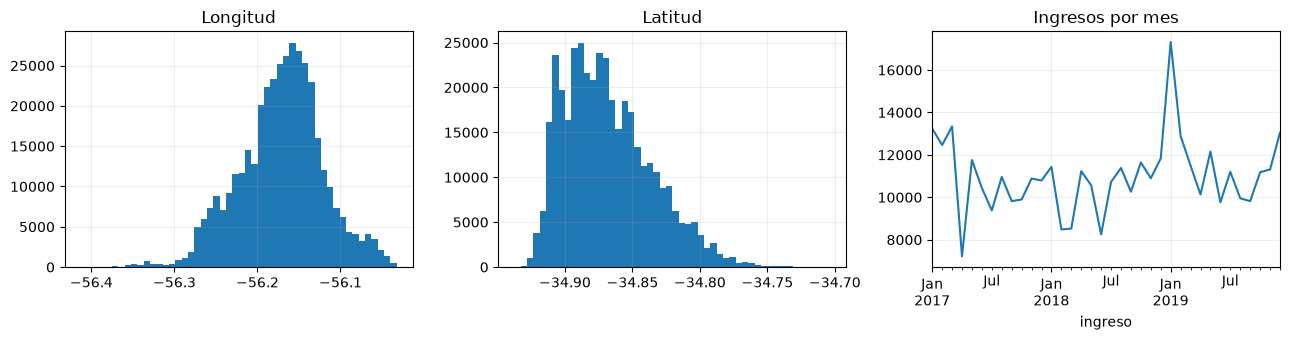

,paso,reclamos,exclusion,sesgo
0,Ventana 2017–2019,395643,Ninguno,Años prepandemia
1,Sin copias,395629,14 copias,Se supone duplicación de publicación
2,Finalizados,378137,17492 abiertos/anulados,Condiciona al cierre registrado
3,Demora válida,378136,1 negativas/ausentes,Resultado desconocido de los excluidos
4,Población final,378136,0 ubicaciones inválidas,Geolocalizables; rectángulo no es límite oficial


,anio,size,mean
0,2017,125135,0.331602
1,2018,119790,0.405660
2,2019,133211,0.428583


Demora en días:
count    378136.000000
mean        150.633677
std         357.939154
min           0.000000
50%          13.000000
90%         533.000000
99%        1776.000000
max        3558.000000
Name: dias, dtype: float64


,defecto,evidencia,decision
0,Copias exactas,14,Eliminar antes de particionar
1,No finalizados,17492,Excluir: fecha actual no es cierre observable
2,Demoras imposibles/ausentes,1,Excluir antes de etiquetar
3,Coordenadas,CSV LATITUD/LONGITUD; metadatos COORD_X/Y UTM,Usar grados y proyectar localmente
4,Estados por año,Tabla estados_por_anio,Declarar sesgo de selección por cierre
5,Precisión de fechas,{0: 378136},"Usar calendario diario, no hora"


,columna,razon,motivo
0,NUMERO_RECLAMO,"Identificador, no describe el problema",Identificación
1,CODIGO_ESTADO / DESC_ESTADO,Estado actual; define población,Disponibilidad
2,FECHA_DESDE_EN_ESTADO,Fecha posterior; construye la respuesta,Disponibilidad
3,FECHA_INGRESO_RECLAMO,Se transforma a calendario,Representación
4,DESC_AREA / DESC_GRUPO / DESC_TIPOPROBLEMA,"Se usan códigos categóricos, no duplicar nombres",Redundancia
5,dias / resuelto_7d / anio,"Respuesta y partición, no entradas",Respuesta/partición


In [2]:
manifest=json.loads(MANIFIESTO.read_text(encoding='utf-8'))
assert hashlib.sha256(ZIP_ORIGINAL.read_bytes()).hexdigest()==manifest['reclamos.zip']['sha256']
if not ARCHIVO.exists():
    with zipfile.ZipFile(ZIP_ORIGINAL) as z:
        with z.open('Reclamos.csv') as origen,ARCHIVO.open('wb') as destino:
            import shutil;shutil.copyfileobj(origen,destino)
crudo=pd.read_csv(ARCHIVO,low_memory=False)
crudo['ingreso']=pd.to_datetime(crudo.FECHA_INGRESO_RECLAMO,errors='coerce')
crudo['estado_desde']=pd.to_datetime(crudo.FECHA_DESDE_EN_ESTADO,errors='coerce')
print('Original:',crudo.shape,'fechas de ingreso inválidas:',crudo.ingreso.isna().sum())
print(METADATOS.read_text(encoding='utf-8-sig'))
ventana=crudo.loc[crudo.ingreso.dt.year.between(2017,2019)].copy()
ventana['anio']=ventana.ingreso.dt.year
guardar('filas_por_anio',ventana.groupby('anio').size().rename('reclamos').reset_index())
guardar('estados_por_anio',pd.crosstab(ventana.anio,ventana.DESC_ESTADO).reset_index())
guardar('auditoria_columnas',pd.DataFrame({'columna':crudo.columns,'tipo':crudo.dtypes.astype(str).values,
 'faltantes':crudo.isna().sum().values,'cardinalidad':crudo.nunique().values}))
print(ventana[['LATITUD','LONGITUD']].describe())
for col in ['DESC_AREA','DESC_GRUPO','DESC_TIPOPROBLEMA']:
    print('\nDistribución',col);print(ventana[col].value_counts().to_string())
fig,ax=plt.subplots(1,3,figsize=(13,3.5))
ventana.LONGITUD.hist(bins=50,ax=ax[0]);ax[0].set_title('Longitud')
ventana.LATITUD.hist(bins=50,ax=ax[1]);ax[1].set_title('Latitud')
ventana.groupby(ventana.ingreso.dt.to_period('M')).size().plot(ax=ax[2]);ax[2].set_title('Ingresos por mes')
plt.tight_layout();plt.show()
pasos=[['Ventana 2017–2019',len(ventana),'Ninguno','Años prepandemia']]
duplicadas=ventana.duplicated(subset=list(crudo.columns)).sum()
datos=ventana.drop_duplicates(subset=list(crudo.columns)).copy()
assert datos.NUMERO_RECLAMO.is_unique,'IDs conflictivos: inspeccionar antes de continuar'
pasos.append(['Sin copias',len(datos),f'{duplicadas} copias','Se supone duplicación de publicación'])
no_final=(datos.DESC_ESTADO!='Finalizado').sum();datos=datos[datos.DESC_ESTADO=='Finalizado'].copy()
pasos.append(['Finalizados',len(datos),f'{no_final} abiertos/anulados','Condiciona al cierre registrado'])
datos['dias']=(datos.estado_desde-datos.ingreso).dt.total_seconds()/86400
invalidos=(datos.dias.isna()|(datos.dias<0)).sum();datos=datos[datos.dias.notna()&(datos.dias>=0)].copy()
pasos.append(['Demora válida',len(datos),f'{invalidos} negativas/ausentes','Resultado desconocido de los excluidos'])
geo=datos.LATITUD.between(-35.1,-34.5)&datos.LONGITUD.between(-56.6,-55.9)
n_geo=(~geo).sum();datos=datos[geo].sort_values('ingreso').reset_index(drop=True)
pasos.append(['Población final',len(datos),f'{n_geo} ubicaciones inválidas','Geolocalizables; rectángulo no es límite oficial'])
guardar('poblacion',pd.DataFrame(pasos,columns=['paso','reclamos','exclusion','sesgo']))
datos['resuelto_7d']=(datos.dias<=7).astype(int)
guardar('prevalencia_anual',datos.groupby('anio').resuelto_7d.agg(['size','mean']).reset_index())
print('Demora en días:');print(datos.dias.describe(percentiles=[.5,.9,.99]))
hallazgos=[['Copias exactas',str(duplicadas),'Eliminar antes de particionar'],
 ['No finalizados',str(no_final),'Excluir: fecha actual no es cierre observable'],
 ['Demoras imposibles/ausentes',str(invalidos),'Excluir antes de etiquetar'],
 ['Coordenadas','CSV LATITUD/LONGITUD; metadatos COORD_X/Y UTM','Usar grados y proyectar localmente'],
 ['Estados por año','Tabla estados_por_anio','Declarar sesgo de selección por cierre'],
 ['Precisión de fechas',str(datos.ingreso.dt.hour.value_counts().to_dict()),'Usar calendario diario, no hora']]
guardar('hallazgos',pd.DataFrame(hallazgos,columns=['defecto','evidencia','decision']))
exclusiones=[['NUMERO_RECLAMO','Identificador, no describe el problema','Identificación'],
 ['CODIGO_ESTADO / DESC_ESTADO','Estado actual; define población','Disponibilidad'],
 ['FECHA_DESDE_EN_ESTADO','Fecha posterior; construye la respuesta','Disponibilidad'],
 ['FECHA_INGRESO_RECLAMO','Se transforma a calendario','Representación'],
 ['DESC_AREA / DESC_GRUPO / DESC_TIPOPROBLEMA','Se usan códigos categóricos, no duplicar nombres','Redundancia'],
 ['dias / resuelto_7d / anio','Respuesta y partición, no entradas','Respuesta/partición']]
guardar('columnas_excluidas',pd.DataFrame(exclusiones,columns=['columna','razon','motivo']))
for col in ['CODIGO_AREA','CODIGO_GRUPO','CODIGO_TIPOPROBLEMA']:datos[col]=datos[col].astype(str)
datos['dia_indice']=(datos.ingreso-pd.Timestamp('2017-01-01')).dt.days
for nombre,val,periodo in [('mes',datos.ingreso.dt.month-1,12),('semana',datos.ingreso.dt.dayofweek,7)]:
    datos[nombre+'_sin']=np.sin(2*np.pi*val/periodo);datos[nombre+'_cos']=np.cos(2*np.pi*val/periodo)
CAT=['CODIGO_AREA','CODIGO_GRUPO','CODIGO_TIPOPROBLEMA']
NUM=['dia_indice','mes_sin','mes_cos','semana_sin','semana_cos']
GEO=['LONGITUD','LATITUD'];FEATURES=CAT+NUM+GEO
desarrollo=datos[datos.anio<2019].copy();prueba=datos[datos.anio==2019].copy()
indices=train_test_split(np.arange(len(desarrollo)),train_size=50000,random_state=SEMILLA,stratify=desarrollo.anio)[0]
muestra=desarrollo.iloc[indices].sort_values('ingreso').reset_index(drop=True)
X=muestra[FEATURES];y=muestra.resuelto_7d.to_numpy()
it=np.flatnonzero(muestra.anio.to_numpy()==2017);iv=np.flatnonzero(muestra.anio.to_numpy()==2018)
CV=[(it,iv)]
sv_idx=train_test_split(np.arange(len(muestra)),train_size=10000,random_state=SEMILLA,stratify=muestra.anio)[0]
Xs=X.iloc[sv_idx].reset_index(drop=True);ys=y[sv_idx];sv_anio=muestra.anio.iloc[sv_idx].to_numpy()
CVS=[(np.flatnonzero(sv_anio==2017),np.flatnonzero(sv_anio==2018))]
RES['datos']={'original':len(crudo),'ventana':len(ventana),'poblacion':len(datos),'desarrollo':len(desarrollo),
 'prueba':len(prueba),'muestra':len(X),'train_2017':len(it),'validacion_2018':len(iv),'copias':int(duplicadas),
 'no_final':int(no_final),'demoras_invalidas':int(invalidos),'geo_invalidas':int(n_geo)}
del crudo


**Población y respuesta.** Cierre registrado como Finalizado en siete días corridos o menos. Según el catálogo, Finalizado puede incluir cierres por no corresponder: no garantiza reparación física. No se confunde la fecha de En Proceso con resolución, ni se etiqueta automáticamente Anulado como fracaso. Excluir abiertos y anulados permite observar una etiqueta, pero condiciona la población a un estado futuro. La tabla anterior cuantifica cada exclusión y su sesgo.

**Contraste con metadatos.** La descripción publicada habla de COORD_X/COORD_Y en UTM; el archivo real tiene LATITUD/LONGITUD en grados. Se respeta el archivo observado y se proyecta localmente. No se interpretan grados como metros. Fechas de precisión diaria impiden analizar horas exactas.

**Entradas.** Códigos de área, grupo y tipo se tratan como categorías, no magnitudes: los niveles amplios pueden aportar ante tipos raros. Se descartan sus nombres redundantes. Fecha relativa y ciclos mensual/semanal representan calendario; identificador, estado y fecha de cambio de estado quedan fuera por razones distintas, explicitadas en la tabla.

**Validación:** entrenar con ingresos de 2017 y validar en 2018. Se descarta mezclar filas como criterio principal porque el uso recibe reclamos posteriores y cambian prevalencia y catálogo. No es una media de cinco folds; es una única frontera anual. La muestra común tiene 50.000 casos estratificados por año. 2019 queda reservado para las secciones 7 y 8.

**Límite temporal:** el archivo es una foto retrospectiva. Algunas etiquetas de ingresos de 2017 se registraron después de 2018. Para simular estrictamente un despliegue histórico habría que cortar también la disponibilidad de etiquetas en cada frontera y reconstruir reaperturas. Se declara esa limitación: el ejercicio evalúa transferencia por año de ingreso, no disponibilidad histórica completa de las etiquetas.

<!-- resultados-verificados -->

**Lectura de los conteos:** 395,643 ingresos en ventana; 14 copias, 17,492 no finalizados y 1 demora inválida excluidos. Quedan 378,136, con 133,211 de prueba. El cierre no equivale necesariamente a reparación física.


## 2. Línea base

Antes de ajustar el primer modelo, reportar la línea base trivial —predecir para todos la prevalencia— y una regresión logística sobre el tipo de problema y la fecha de ingreso, sin la ubicación.

Las métricas son el ROC-AUC (AUC) y la average precision (AP). Leer la AP de la línea base trivial y decir por qué no es cero. Todo número posterior se informa contra esta línea base.

In [3]:
class Coordenadas(BaseEstimator,TransformerMixin):
    def __init__(self,unidad='metros',escalar=True):self.unidad=unidad;self.escalar=escalar
    def convertir(self,X):
        a=np.asarray(X,dtype=float)
        if self.unidad=='grados':return a
        lon=np.radians(a[:,0]);lat=np.radians(a[:,1]);lon0=np.radians(-56.17);lat0=np.radians(-34.87)
        return np.column_stack([6371000*(lon-lon0)*np.cos(lat0),6371000*(lat-lat0)])
    def fit(self,X,y=None):
        a=self.convertir(X);self.centro_=np.nanmean(a,axis=0)
        self.factor_=float(np.sqrt(np.nanmean(np.nanvar(a,axis=0)))) if self.escalar else 1.
        if not self.factor_:self.factor_=1.
        return self
    def transform(self,X):
        a=self.convertir(X)
        return (a-self.centro_)/self.factor_ if self.escalar else a
    def get_feature_names_out(self,input_features=None):return np.array(['espacio_x','espacio_y'],dtype=object)
def preparar(ubicacion=True,unidad='metros',escalar=True,zona_k=None):
    ramas=[('tipo',Pipeline([('imputar',SimpleImputer(strategy='constant',fill_value='sin_dato')),
      ('onehot',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]),CAT),
      ('calendario',Pipeline([('imputar',SimpleImputer(strategy='median')),('escala',StandardScaler())]),NUM)]
    if ubicacion:
        pasos=[('coordenadas',Coordenadas(unidad,escalar))]
        if zona_k is not None:pasos.append(('zonas',KMeans(n_clusters=zona_k,n_init=10,random_state=SEMILLA)))
        ramas.append(('ubicacion',Pipeline(pasos),GEO))
    return ColumnTransformer(ramas,remainder='drop')
def flujo(modelo,**opciones):return Pipeline([('preparar',preparar(**opciones)),('modelo',modelo)])
BASE={}
p,tf,tp=reloj_fit_predict(DummyClassifier(strategy='prior'),X.iloc[it],y[it],X.iloc[iv])
BASE['Prevalencia']=metricas(y[iv],p)
log_sin=flujo(LogisticRegression(max_iter=1500),ubicacion=False)
p,tf,tp=reloj_fit_predict(log_sin,X.iloc[it],y[it],X.iloc[iv])
BASE['Logística sin ubicación']=metricas(y[iv],p)
guardar('lineas_base',pd.DataFrame([{'modelo':k,**v} for k,v in BASE.items()]))
RES['base']=BASE
mostrar(f'La AP trivial es {BASE["Prevalencia"]["AP"]:.3f}: coincide con prevalencia de **validación**, no con cero. La probabilidad constante empata los riesgos y tiene AUC=0,5. La logística sin ubicación es la referencia predictiva posterior.')


,modelo,AUC,AP
0,Prevalencia,0.500000,0.402634
1,Logística sin ubicación,0.707508,0.626176


La AP trivial es 0.403: coincide con prevalencia de **validación**, no con cero. La probabilidad constante empata los riesgos y tiene AUC=0,5. La logística sin ubicación es la referencia predictiva posterior.

Se ajusta solo en 2017 y se evalúa en 2018. AP es average precision, no accuracy: para puntuaciones constantes su referencia es la prevalencia del conjunto evaluado. No se necesita un umbral ni se elige uno por costos. Las tablas ejecutadas reemplazan cifras hipotéticas y toda comparación posterior informa ambas referencias.


## 3. Coordenadas: qué necesita cada familia

La guía del enunciado dice qué conviene hacer con las coordenadas y por qué. Esta sección la corrobora experimentalmente con k vecinos y un árbol de decisión, sobre el mismo esquema de validación, comparando dos pares de variantes. En cada par cambia una sola cosa:

1. La unidad. Coordenadas en grados contra coordenadas en metros.
2. La escala de las coordenadas frente a las demás entradas. Coordenadas en metros estandarizadas, de modo que queden en una escala comparable con el resto, contra coordenadas en metros sin escalar, con valores de miles al lado de columnas indicadoras de 0 y 1.

Si un cambio no mueve la métrica, decirlo y explicarlo es una respuesta correcta.

In [4]:
filas=[]
for familia,modelo in [('KNN',KNeighborsClassifier(n_neighbors=31,n_jobs=2)),
 ('Árbol',DecisionTreeClassifier(max_depth=8,min_samples_leaf=30,random_state=SEMILLA))]:
    for par,nombre,unidad,escala in [('Unidad','Grados','grados',False),('Unidad','Metros','metros',False),
       ('Escala','Metros estandarizados','metros',True),('Escala','Metros sin escalar','metros',False)]:
        mod=flujo(clone(modelo),unidad=unidad,escalar=escala)
        p,tf,tp=reloj_fit_predict(mod,X.iloc[it],y[it],X.iloc[iv])
        filas.append({'par':par,'variante':nombre,'familia':familia,**metricas(y[iv],p)})
guardar('experimento_coordenadas',pd.DataFrame(filas));RES['coordenadas']=filas


,par,variante,familia,AUC,AP
0,Unidad,Grados,KNN,0.675960,0.587850
1,Unidad,Metros,KNN,0.579709,0.454632
2,Escala,Metros estandarizados,KNN,0.701058,0.606339
3,Escala,Metros sin escalar,KNN,0.579709,0.454632
4,Unidad,Grados,Árbol,0.650173,0.566134
5,Unidad,Metros,Árbol,0.650173,0.566134
6,Escala,Metros estandarizados,Árbol,0.650173,0.566134
7,Escala,Metros sin escalar,Árbol,0.650173,0.566134


**Proyección:** aproximación local de la consigna, radio 6.371.000 m y referencia fija (-56,17°, -34,87°). Las fórmulas usan radianes. Es una aproximación local, no un levantamiento geodésico.

En cada par se cambia una sola cosa: grados/metros, o el factor de escala espacial. Tipo, calendario, hiperparámetros y partición permanecen iguales. El factor espacial común se aprende solo en entrenamiento y preserva la geometría; dividir cada eje por su propio desvío la deformaría.

KNN combina las entradas en una distancia y puede cambiar sus vecinos. El árbol puede mover umbrales sin cambiar grupos ante la transformación afín positiva de cada eje que usamos. Se leen los cambios medidos; no se presupone que toda métrica tenga que moverse o mejorar.

<!-- resultados-verificados -->

**Resultado medido:** KNN pasa de AUC 0,676 en grados sin escalar a 0,580 en metros sin escalar; con metros estandarizados alcanza 0,701. Cambiar a una unidad física correcta sin controlar su peso frente al resto no garantiza mejor predicción. El árbol conserva AUC 0,650 y AP 0,566 en las cuatro variantes: sus particiones no cambian en este experimento.


## 4. Focos espaciales

Elegir un tipo de problema con al menos 2000 reclamos en 2017–2018, justificar la elección y agrupar sus ubicaciones —solo las de 2017–2018— con tres métodos:

- k-medias, con $K$ elegido a partir de la curva del silhouette score en función de $K$, interpretando la forma de la curva;
- jerárquico aglomerativo, con enlace de Ward y con enlace simple;
- DBSCAN, con $\varepsilon$ y el mínimo de vecinos elegidos a partir de un gráfico de k-distancias construido antes de agrupar.

Mostrar cada resultado sobre un mapa —un gráfico de dispersión de las coordenadas alcanza— e interpretarlo en el lenguaje del caso. Para DBSCAN, declarar cómo se trató el ruido al calcular el silhouette score.

Recomendar un conjunto concreto de focos, con su ubicación aproximada, su tamaño y el criterio que lo sostiene.

Tipo 401: <StringArray>
['Bache']
Length: 1, dtype: str reclamos: 4626


,K,silhouette
0,2,0.440279
1,3,0.421655
2,4,0.466453
3,6,0.433629
4,8,0.420542
5,10,0.404409
6,12,0.399375


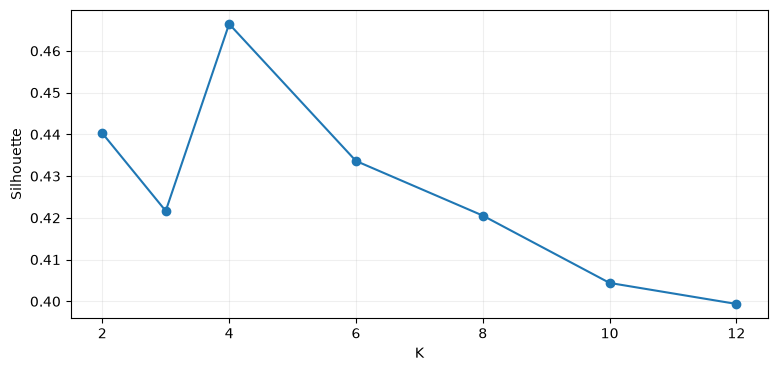

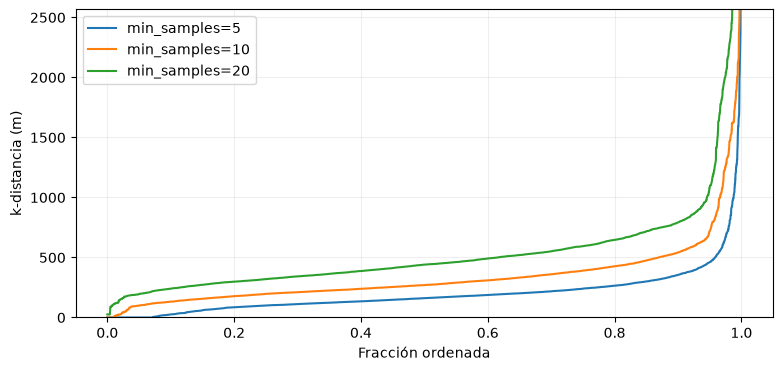

min_samples: 10 eps: 542.9 m; percentil: 0.901


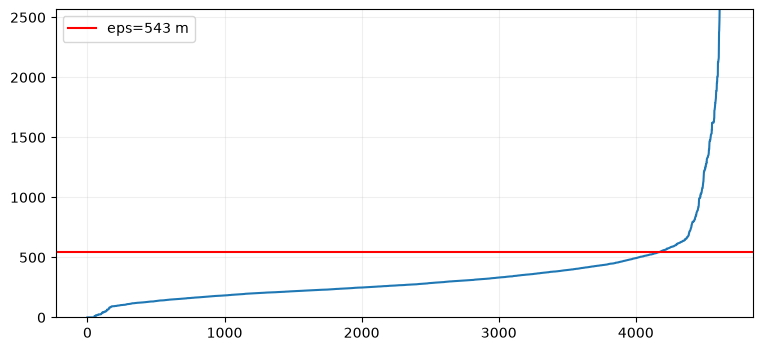

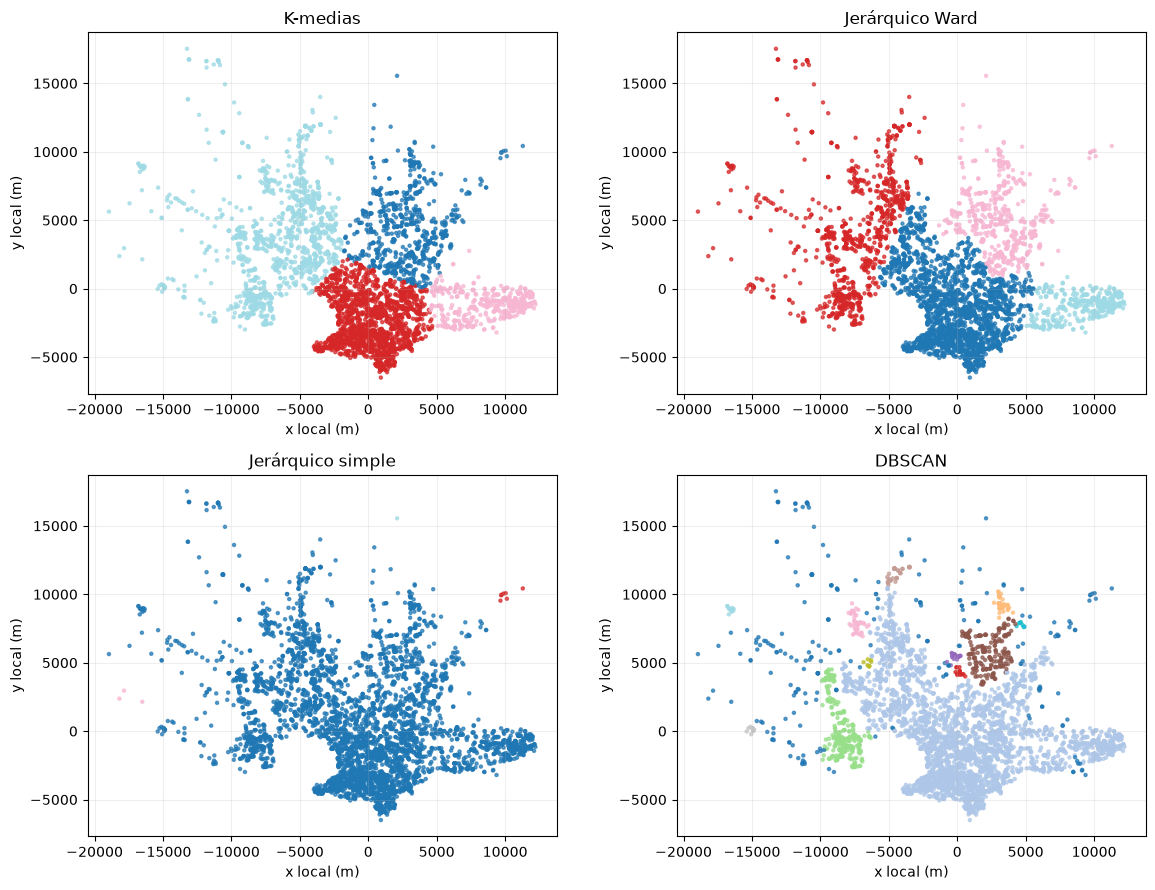

,metodo,grupos,sin_grupo,silhouette,cobertura
0,K-medias,4,0,0.466453,1.000000
1,Jerárquico Ward,4,0,0.415643,1.000000
2,Jerárquico simple,4,0,0.325177,1.000000
3,DBSCAN,12,232,-0.006440,0.949849


,foco,longitud,latitud,reclamos,radio_p90_m,criterio
0,0,-56.161647,-34.873471,3672,9369.680842,"Densidad: eps 543 m, min_samples 10"
2,2,-56.261673,-34.869191,287,3859.312841,"Densidad: eps 543 m, min_samples 10"
5,5,-56.144647,-34.818495,225,2128.618671,"Densidad: eps 543 m, min_samples 10"
7,7,-56.250948,-34.797723,50,955.737668,"Densidad: eps 543 m, min_samples 10"
1,1,-56.134425,-34.786864,44,755.603047,"Densidad: eps 543 m, min_samples 10"
6,6,-56.218953,-34.766353,42,1074.901510,"Densidad: eps 543 m, min_samples 10"
4,4,-56.171297,-34.821079,21,394.032001,"Densidad: eps 543 m, min_samples 10"
3,3,-56.168164,-34.831223,14,414.564745,"Densidad: eps 543 m, min_samples 10"
11,11,-56.351658,-34.789915,12,316.195321,"Densidad: eps 543 m, min_samples 10"
8,8,-56.334635,-34.869001,11,337.404752,"Densidad: eps 543 m, min_samples 10"


,foco,longitud,latitud,reclamos,radio_p90_m,criterio
5,5,-56.144647,-34.818495,225,2128.618671,"Densidad: eps 543 m, min_samples 10"
7,7,-56.250948,-34.797723,50,955.737668,"Densidad: eps 543 m, min_samples 10"
1,1,-56.134425,-34.786864,44,755.603047,"Densidad: eps 543 m, min_samples 10"
6,6,-56.218953,-34.766353,42,1074.901510,"Densidad: eps 543 m, min_samples 10"


K con mayor silhouette observado: 4. DBSCAN identifica 12 grupos. Ruido excluido de silhouette y reportado como sin grupo: no se considera una sola agrupación de puntos dispersos. Si hay menos de dos grupos, silhouette no está definido.

In [5]:
# Focos de ingresos: también se incluyen abiertos y anulados; solo 2017–2018.
T=ventana[(ventana.anio<2019)&(ventana.CODIGO_TIPOPROBLEMA==401)].drop_duplicates(subset='NUMERO_RECLAMO').copy()
T=T[T.LATITUD.between(-35.1,-34.5)&T.LONGITUD.between(-56.6,-55.9)]
assert len(T)>=2000
print('Tipo 401:',T.DESC_TIPOPROBLEMA.unique(),'reclamos:',len(T))
P=Coordenadas(escalar=False).fit_transform(T[GEO])
KS=[2,3,4,6,8,10,12];curva=[];ajustes={}
for k in KS:
    km=KMeans(n_clusters=k,n_init=10,random_state=SEMILLA).fit(P)
    s=silhouette_score(P,km.labels_,sample_size=min(2500,len(P)),random_state=SEMILLA)
    curva.append({'K':k,'silhouette':s});ajustes[k]=km
curva=pd.DataFrame(curva);guardar('curva_kmeans',curva)
plt.plot(curva.K,curva.silhouette,'o-');plt.xlabel('K');plt.ylabel('Silhouette');plt.show()
K_FOCOS=int(curva.loc[curva.silhouette.idxmax(),'K'])
# Diagnóstico ANTES de DBSCAN: varios mínimos, sin elegir por etiquetas resultantes.
distancias={};fig,ax=plt.subplots()
for minimo in [5,10,20]:
    d=NearestNeighbors(n_neighbors=minimo).fit(P).kneighbors(P)[0][:,-1]
    distancias[minimo]=np.sort(d)
    ax.plot(np.linspace(0,1,len(d)),np.sort(d),label=f'min_samples={minimo}')
ax.set_ylim(0,np.quantile(distancias[10],.995)*1.2);ax.set_xlabel('Fracción ordenada');ax.set_ylabel('k-distancia (m)');ax.legend();plt.show()
MIN_VECINOS=10;d=distancias[MIN_VECINOS];n=int(len(d)*.99);central=d[:n]
# Rodilla = máxima separación de recta extremo-extremo en el 99% central.
normal=(central-central[0])/(central[-1]-central[0]);separacion=np.linspace(0,1,n)-normal
rodilla=int(np.argmax(separacion));EPS=float(central[rodilla])
print('min_samples:',MIN_VECINOS,'eps:',round(EPS,1),'m; percentil:',round(rodilla/len(d),3))
plt.plot(d);plt.axhline(EPS,color='red',label=f'eps={EPS:.0f} m');plt.ylim(0,np.quantile(d,.995)*1.2);plt.legend();plt.show()
labels={'K-medias':ajustes[K_FOCOS].labels_,
 'Jerárquico Ward':AgglomerativeClustering(n_clusters=K_FOCOS,linkage='ward').fit_predict(P),
 'Jerárquico simple':AgglomerativeClustering(n_clusters=K_FOCOS,linkage='single').fit_predict(P),
 'DBSCAN':DBSCAN(eps=EPS,min_samples=MIN_VECINOS,n_jobs=2).fit_predict(P)}
filas=[];fig,axes=plt.subplots(2,2,figsize=(12,9))
for (nombre,lab),ax in zip(labels.items(),axes.ravel()):
    ok=lab!=-1;grupos=len(set(lab[ok]));sil=np.nan
    if grupos>=2 and ok.sum()>grupos:
        sil=silhouette_score(P[ok],lab[ok],sample_size=min(2500,int(ok.sum())),random_state=SEMILLA)
    filas.append({'metodo':nombre,'grupos':grupos,'sin_grupo':int((~ok).sum()),'silhouette':sil,'cobertura':float(ok.mean())})
    ax.scatter(P[:,0],P[:,1],c=lab,cmap='tab20',s=5,alpha=.7);ax.set_title(nombre);ax.set_aspect('equal');ax.set_xlabel('x local (m)');ax.set_ylabel('y local (m)')
plt.tight_layout();plt.show();guardar('comparacion_clusters',pd.DataFrame(filas))
lab=labels['DBSCAN'];f=[]
for grupo in sorted(set(lab)-{-1}):
    idx=lab==grupo;centro=P[idx].mean(axis=0)
    f.append({'foco':int(grupo),'longitud':float(T.LONGITUD.to_numpy()[idx].mean()),'latitud':float(T.LATITUD.to_numpy()[idx].mean()),
      'reclamos':int(idx.sum()),'radio_p90_m':float(np.quantile(np.linalg.norm(P[idx]-centro,axis=1),.9)),
      'criterio':f'Densidad: eps {EPS:.0f} m, min_samples {MIN_VECINOS}'})
focos=pd.DataFrame(f).sort_values('reclamos',ascending=False) if f else pd.DataFrame(columns=['foco','reclamos','radio_p90_m'])
guardar('grupos_dbscan',focos)
# No recomendar como intervención conjunta el gran grupo que encadena la ciudad.
# Criterio operativo propuesto para revisión: soporte >=30 y radio p90 <=2,5 km.
recomendados=focos[(focos.reclamos>=30)&(focos.radio_p90_m<=2500)].head(5)
guardar('focos_recomendados',recomendados)
RES['focos']={'tipo':'Bache (401)','reclamos':len(T),'K':K_FOCOS,'eps':EPS,'min_samples':MIN_VECINOS,'comparacion':filas,'recomendados':recomendados.to_dict('records')}
mostrar(f'K con mayor silhouette observado: {K_FOCOS}. DBSCAN identifica {len(focos)} grupos. Ruido excluido de silhouette y reportado como sin grupo: no se considera una sola agrupación de puntos dispersos. Si hay menos de dos grupos, silhouette no está definido.')


**Elección:** baches (tipo 401), problema localizado y con más de 2.000 ingresos de desarrollo. Se incluyen estados no finales para medir concentración de reportes, no solo de cierres. La tabla da las ubicaciones aproximadas de hasta cinco focos compactos con más soporte y su radio p90.

**K-medias:** se elige K por la curva completa; un máximo en la grilla no prueba un número natural de barrios, especialmente si la curva es plana o cae desde K=2. Se conserva ese K en Ward y enlace simple para comparar enlaces. Ward favorece compacidad; simple puede encadenar puntos por puentes.

**DBSCAN:** se comparan k-distancias de 5, 10 y 20 vecinos, se fija 10 como soporte intermedio y se calcula una rodilla antes de agrupar. La regla de máxima separación de recta usa el 99% central para no elegir por un único extremo. Es una aproximación discutible, no un radio municipal oficial. Se informa cobertura junto con silhouette: excluir mucho ruido puede mejorar esa métrica sin representar toda la ciudad.

K-medias reparte todos los puntos en zonas; DBSCAN busca densidad y puede dejar ruido, pero también puede encadenar gran parte de la ciudad en un grupo. El mejor silhouette no elige automáticamente la mejor intervención. Para recomendar focos se exige al menos 30 reportes y radio p90 de hasta 2,5 km: criterio operativo propuesto, no norma oficial ni parámetro ajustado sobre 2019. Se excluyen grupos demasiado extensos de la recomendación y se muestran todos en la tabla. Sus centros son coordenadas aproximadas, no barrios identificados por nombre. Los reportes pueden ser reiteraciones: no cuentan baches físicos únicos ni incidencia por población.

<!-- resultados-verificados -->

**Lectura de la curva y mapas:** silhouette tiene máximo interior en K=4 (0,466), por encima de K=3 (0,422) y K=6 (0,434), aunque no demuestra cuatro zonas naturales únicas. DBSCAN produce 12 grupos y 232 puntos de ruido (cobertura 95.0%), con silhouette -0.006. El mayor grupo encadena miles de reclamos y no se recomienda como foco compacto. La tabla de focos filtra por soporte y radio p90; un silhouette negativo impide presentar todo el agrupamiento como separación exitosa.


## 5. El agrupamiento como atributo

Usar un agrupamiento de las ubicaciones como entrada de la regresión logística: zonas de k-medias ajustadas sobre las coordenadas, representadas por la etiqueta de la zona o por las distancias a los centroides. Comparar, sobre el mismo esquema de validación, la logística con las coordenadas crudas contra la logística con las zonas, y explicar con qué criterio se eligió $K$.

El agrupamiento es una transformación que aprende de los datos, y como toda transformación de ese tipo va dentro del `Pipeline`. Explicar qué cambia si se lo ajusta afuera, y qué pasaría con cualquier representación de la zona que use la respuesta.

In [6]:
log_coord=flujo(LogisticRegression(max_iter=1500))
p,tf,tp=reloj_fit_predict(log_coord,X.iloc[it],y[it],X.iloc[iv])
comparacion=[{'modelo':'Logística coordenadas',**metricas(y[iv],p)}]
# KMeans.transform devuelve distancias a centros y aprende dentro de cada fit.
bus_zonas=GridSearchCV(flujo(LogisticRegression(max_iter=1500),zona_k=4),
 {'preparar__ubicacion__zonas__n_clusters':[4,8,12]},scoring={'AUC':'roc_auc','AP':'average_precision'},refit='AP',cv=CV,n_jobs=1).fit(X,y)
K_ZONAS=int(bus_zonas.best_params_['preparar__ubicacion__zonas__n_clusters']);ind=bus_zonas.best_index_
comparacion.append({'modelo':f'Logística distancias a {K_ZONAS} centros','AUC':float(bus_zonas.cv_results_['mean_test_AUC'][ind]),'AP':float(bus_zonas.cv_results_['mean_test_AP'][ind])})
guardar('logistica_zonas',pd.DataFrame(comparacion));RES['zonas']={'K':K_ZONAS,'comparacion':comparacion}


,modelo,AUC,AP
0,Logística coordenadas,0.725404,0.648177
1,Logística distancias a 12 centros,0.743277,0.663005


Se eligen distancias a centroides para no imponer orden a etiquetas de zona. K se selecciona por AP temporal entre 4, 8 y 12, sobre todos los tipos. El K de focos de baches no se supone óptimo para predicción general. La logística con x/y tiene un efecto espacial lineal en log-odds; las distancias agregan una representación no lineal. La mejora se mide, no se garantiza.

KMeans está dentro del pipeline y aprende solo de entrenamiento. Ajustarlo antes con toda la muestra revelaría distribución de ubicaciones de validación. Una representación que use la respuesta (por ejemplo, tasa de cierre por zona) requeriría construcción fuera de muestra dentro de cada partición para evitar fuga de etiquetas. Aquí no se usa la respuesta para agrupar. Si se usaran etiquetas de zona, se codificarían como categorías, no como números ordenados.

<!-- resultados-verificados -->

**Resultado:** AP temporal sube de 0.648 con coordenadas directas a 0.663 con distancias a 12 centroides; diferencia +0.015. Frente a la logística sin ubicación (AP 0.626), ambas representaciones aportan en esta frontera. K=12 es el extremo superior de la grilla; no se afirma que sea el óptimo global.


## 6. Seis familias con ajuste de hiperparámetros

Ajustar sobre la misma preparación k vecinos más cercanos, un árbol de decisión, una máquina de vectores de soporte con núcleo RBF, un bosque aleatorio, un modelo de boosting y una red neuronal, cada uno con sus hiperparámetros elegidos con el esquema de validación de la sección 1.

- Se trabaja con una submuestra de 50 000 reclamos de 2017–2018, estratificada por año y la misma para todas las familias. La máquina de vectores de soporte usa 10 000 de esos 50 000.
- Las grillas se declaran. Alcanzan dos a cuatro valores por hiperparámetro, sobre los hiperparámetros que más pesan en cada familia. Si el valor elegido queda en un borde de la grilla, se dice.
- Se registra el tiempo de ajuste y de predicción de cada familia.

No se toca 2019.

In [7]:
FAMILIAS={
 'KNN':(KNeighborsClassifier(n_jobs=2),{'modelo__n_neighbors':[15,51,151]}),
 'Árbol':(DecisionTreeClassifier(random_state=SEMILLA),{'modelo__max_depth':[6,12],'modelo__min_samples_leaf':[20,60]}),
 'SVM RBF':(SVC(kernel='rbf',cache_size=800),{'modelo__C':[.5,2.],'modelo__gamma':['scale',.03]}),
 'Bosque':(RandomForestClassifier(n_estimators=120,max_features='sqrt',n_jobs=2,random_state=SEMILLA),
    {'modelo__max_depth':[10,None],'modelo__min_samples_leaf':[5,20]}),
 'Boosting':(GradientBoostingClassifier(random_state=SEMILLA,learning_rate=.1,subsample=.8),
    {'modelo__n_estimators':[60,100],'modelo__max_depth':[2,3]}),
 'Red neuronal':(MLPClassifier(max_iter=120,early_stopping=True,n_iter_no_change=10,random_state=SEMILLA),
    {'modelo__hidden_layer_sizes':[(32,),(64,)],'modelo__alpha':[.001,.1]})}
ELEGIDOS={};VALIDACION=[]
for nombre,(modelo,grilla) in FAMILIAS.items():
    xx,yy,cv=(Xs,ys,CVS) if nombre=='SVM RBF' else (X,y,CV)
    print('Buscando',nombre,'n=',len(xx),flush=True);t=time.perf_counter()
    bus=GridSearchCV(flujo(clone(modelo)),grilla,scoring={'AUC':'roc_auc','AP':'average_precision'},refit='AP',cv=cv,n_jobs=1,error_score='raise').fit(xx,yy)
    tiempo_busqueda=time.perf_counter()-t;ELEGIDOS[nombre]=clone(bus.best_estimator_)
    a,b=cv[0];p,tf,tp=reloj_fit_predict(clone(bus.best_estimator_),xx.iloc[a],yy[a],xx.iloc[b])
    bordes=[k+'='+str(bus.best_params_[k]) for k,v in grilla.items() if bus.best_params_[k] in (v[0],v[-1])]
    fila={'familia':nombre,'n':len(xx),'configuracion':str(bus.best_params_),'grilla':str(grilla),**metricas(yy[b],p),
          'ajuste_s':tf,'prediccion_s':tp,'busqueda_s':tiempo_busqueda,'bordes':'; '.join(bordes)}
    VALIDACION.append(fila);print(fila,flush=True);guardar('familias_validacion',pd.DataFrame(VALIDACION))
RES['familias_validacion']=VALIDACION
# Regla fijada ANTES de abrir 2019: entre candidatos a 0,01 AP del máximo,
# preferir menor tiempo de ajuste+predicción; explicar capacidad interpretativa.
max_ap=max(f['AP'] for f in VALIDACION)
candidatos=[f for f in VALIDACION if f['AP']>=max_ap-.01]
RECOMENDADO=min(candidatos,key=lambda f:f['ajuste_s']+f['prediccion_s'])['familia']
print('Recomendación fijada en desarrollo:',RECOMENDADO)


Buscando KNN n= 50000


{'familia': 'KNN', 'n': 50000, 'configuracion': "{'modelo__n_neighbors': 51}", 'grilla': "{'modelo__n_neighbors': [15, 51, 151]}", 'AUC': 0.6938954470310471, 'AP': 0.6038072066952402, 'ajuste_s': 0.035788899999715795, 'prediccion_s': 4.689285600000403, 'busqueda_s': 15.721807300000364, 'bordes': ''}


,familia,n,configuracion,grilla,AUC,AP,ajuste_s,prediccion_s,busqueda_s,bordes
0,KNN,50000,{'modelo__n_neighbors': 51},"{'modelo__n_neighbors': [15, 51, 151]}",0.693895,0.603807,0.035789,4.689286,15.721807,


Buscando Árbol n= 50000


{'familia': 'Árbol', 'n': 50000, 'configuracion': "{'modelo__max_depth': 12, 'modelo__min_samples_leaf': 60}", 'grilla': "{'modelo__max_depth': [6, 12], 'modelo__min_samples_leaf': [20, 60]}", 'AUC': 0.6594025331284699, 'AP': 0.579035753933728, 'ajuste_s': 0.1655404000002818, 'prediccion_s': 0.03398430000015651, 'busqueda_s': 1.1909171999996033, 'bordes': 'modelo__max_depth=12; modelo__min_samples_leaf=60'}


...

,familia,n,configuracion,grilla,AUC,AP,ajuste_s,prediccion_s,busqueda_s,bordes
0,KNN,50000,{'modelo__n_neighbors': 51},"{'modelo__n_neighbors': [15, 51, 151]}",0.693895,0.603807,0.035789,4.689286,15.721807,
1,Árbol,50000,"{'modelo__max_depth': 12, 'modelo__min_samples_leaf': 60}","{'modelo__max_depth': [6, 12], 'modelo__min_samples_leaf': [20, 60]}",0.659403,0.579036,0.165540,0.033984,1.190917,modelo__max_depth=12; modelo__min_samples_leaf=60
2,SVM RBF,10000,"{'modelo__C': 2.0, 'modelo__gamma': 0.03}","{'modelo__C': [0.5, 2.0], 'modelo__gamma': ['scale', 0.03]}",0.714534,0.619345,0.486576,0.735525,7.579632,modelo__C=2.0; modelo__gamma=0.03
3,Bosque,50000,"{'modelo__max_depth': None, 'modelo__min_samples_leaf': 5}","{'modelo__max_depth': [10, None], 'modelo__min_samples_leaf': [5, 20]}",0.746855,0.669173,1.223101,0.133847,7.883990,modelo__max_depth=None; modelo__min_samples_leaf=5
4,Boosting,50000,"{'modelo__max_depth': 3, 'modelo__n_estimators': 100}","{'modelo__n_estimators': [60, 100], 'modelo__max_depth': [2, 3]}",0.740835,0.656901,3.397538,0.058402,25.907637,modelo__n_estimators=100; modelo__max_depth=3


Buscando Red neuronal n= 50000


{'familia': 'Red neuronal', 'n': 50000, 'configuracion': "{'modelo__alpha': 0.1, 'modelo__hidden_layer_sizes': (32,)}", 'grilla': "{'modelo__hidden_layer_sizes': [(32,), (64,)], 'modelo__alpha': [0.001, 0.1]}", 'AUC': 0.7514325938455502, 'AP': 0.669021045181172, 'ajuste_s': 1.4850366000000577, 'prediccion_s': 0.04642679999960819, 'busqueda_s': 8.830144999999902, 'bordes': 'modelo__hidden_layer_sizes=(32,); modelo__alpha=0.1'}


,familia,n,configuracion,grilla,AUC,AP,ajuste_s,prediccion_s,busqueda_s,bordes
0,KNN,50000,{'modelo__n_neighbors': 51},"{'modelo__n_neighbors': [15, 51, 151]}",0.693895,0.603807,0.035789,4.689286,15.721807,
1,Árbol,50000,"{'modelo__max_depth': 12, 'modelo__min_samples_leaf': 60}","{'modelo__max_depth': [6, 12], 'modelo__min_samples_leaf': [20, 60]}",0.659403,0.579036,0.165540,0.033984,1.190917,modelo__max_depth=12; modelo__min_samples_leaf=60
2,SVM RBF,10000,"{'modelo__C': 2.0, 'modelo__gamma': 0.03}","{'modelo__C': [0.5, 2.0], 'modelo__gamma': ['scale', 0.03]}",0.714534,0.619345,0.486576,0.735525,7.579632,modelo__C=2.0; modelo__gamma=0.03
3,Bosque,50000,"{'modelo__max_depth': None, 'modelo__min_samples_leaf': 5}","{'modelo__max_depth': [10, None], 'modelo__min_samples_leaf': [5, 20]}",0.746855,0.669173,1.223101,0.133847,7.883990,modelo__max_depth=None; modelo__min_samples_leaf=5
4,Boosting,50000,"{'modelo__max_depth': 3, 'modelo__n_estimators': 100}","{'modelo__n_estimators': [60, 100], 'modelo__max_depth': [2, 3]}",0.740835,0.656901,3.397538,0.058402,25.907637,modelo__n_estimators=100; modelo__max_depth=3
5,Red neuronal,50000,"{'modelo__alpha': 0.1, 'modelo__hidden_layer_sizes': (32,)}","{'modelo__hidden_layer_sizes': [(32,), (64,)], 'modelo__alpha': [0.001, 0.1]}",0.751433,0.669021,1.485037,0.046427,8.830145,"modelo__hidden_layer_sizes=(32,); modelo__alpha=0.1"


Recomendación fijada en desarrollo: Bosque


AP temporal elige hiperparámetros, AUC se reporta también. Se conserva proporción de clases. Cada búsqueda ajusta el pipeline dentro de 2017→2018. SVM usa 10.000 de los 50.000 y sus scores de decisión sirven para AUC/AP, no son probabilidades calibradas.

La preparación es común: categorías one-hot, calendario estandarizado y coordenadas proyectadas con factor común. No se mezcla el experimento de zonas con la comparación de familias. Árboles no necesitan el escalado, pero mantenerlo no altera sus particiones por eje.

Grillas pequeñas: con dos valores ambos son bordes; se informa la limitación, no se afirma óptimo global. Se distinguen tiempo de búsqueda, ajuste de una configuración y predicción. La red usa early stopping sobre una fracción interna de entrenamiento, no sobre 2018 ni 2019. Se revisan avisos de convergencia.

La recomendación se fija en desarrollo: tolerancia operativa de 0,01 AP frente al máximo y menor tiempo de ajuste+predicción entre candidatos cercanos. No es una prueba estadística de equivalencia. Se discute además lo que permite explicar la familia; no se cambia el criterio al ver el test.

<!-- resultados-verificados -->

**Selección real:** el bosque obtuvo AP 0,6692 y la red 0,6690 en desarrollo. La diferencia es de unas diezmilésimas y no elige un ganador por sí sola. La regla de costo de ajuste+predicción entre candidatos cercanos seleccionó Bosque; el bosque ofrece análisis de importancias y no exige una red para un resultado prácticamente igual en validación.


## 7. Validación y comparación final sobre 2019

Entrenar cada familia, con la configuración elegida en la sección 6, sobre la submuestra de 2017–2018, y evaluarla una sola vez sobre 2019.

Para el bosque aleatorio, agregar dos estimaciones más del mismo desempeño: la del esquema de validación de la sección 1 y la de una validación cruzada de $k$ folds con las filas mezcladas al azar, sobre los mismos datos de 2017–2018. Reportar la brecha entre las estimaciones y el resultado sobre 2019 como número, e identificar el mecanismo que la produce.

Elegir un modelo para recomendar, pesando desempeño, costo de cómputo y lo que el modelo permite explicar. Una diferencia de pocas milésimas no elige un modelo.

> Esta sección se apoya en validación temporal, que se dicta más adelante en el curso.

In [8]:
X19=prueba[FEATURES];y19=prueba.resuelto_7d.to_numpy()
FINAL=[];AJUSTADOS={}
for nombre,modelo in [('Logística sin ubicación',clone(log_sin))]+list(ELEGIDOS.items()):
    xx,yy=(Xs,ys) if nombre=='SVM RBF' else (X,y)
    mod=clone(modelo);p,tf,tp=reloj_fit_predict(mod,xx,yy,X19);AJUSTADOS[nombre]=mod
    FINAL.append({'familia':nombre,'n_entrenamiento':len(xx),'n_prueba':len(X19),**metricas(y19,p),'ajuste_s':tf,'prediccion_s':tp})
    print(nombre,FINAL[-1],flush=True)
guardar('familias_2019',pd.DataFrame(FINAL))
aleatorias=[]
for a,b in StratifiedKFold(n_splits=5,shuffle=True,random_state=SEMILLA).split(X,y):
    mod=clone(ELEGIDOS['Bosque']);p,_,_=reloj_fit_predict(mod,X.iloc[a],y[a],X.iloc[b]);aleatorias.append(metricas(y[b],p))
rf_val=next(f for f in VALIDACION if f['familia']=='Bosque');rf_test=next(f for f in FINAL if f['familia']=='Bosque')
ale=pd.DataFrame(aleatorias)
brechas=pd.DataFrame([{'esquema':'Temporal 2017→2018','AUC':rf_val['AUC'],'AP':rf_val['AP']},
 {'esquema':'5 folds mezclados','AUC':ale.AUC.mean(),'AP':ale.AP.mean()},
 {'esquema':'2017–2018 → 2019','AUC':rf_test['AUC'],'AP':rf_test['AP']}])
brechas['brecha_AUC_vs_2019']=brechas.AUC-rf_test['AUC'];brechas['brecha_AP_vs_2019']=brechas.AP-rf_test['AP']
guardar('validacion_bosque',brechas)
mostrar(f'**Recomendado en desarrollo:** {RECOMENDADO}. Se comprueba sobre 2019, sin abrir una nueva búsqueda.')
RES['final']=FINAL;RES['brechas_bosque']=brechas.to_dict('records');RES['recomendado']=RECOMENDADO


Logística sin ubicación {'familia': 'Logística sin ubicación', 'n_entrenamiento': 50000, 'n_prueba': 133211, 'AUC': 0.7456819487373426, 'AP': 0.7062970632816798, 'ajuste_s': 1.1994068999993033, 'prediccion_s': 0.1750064999996539}


KNN {'familia': 'KNN', 'n_entrenamiento': 50000, 'n_prueba': 133211, 'AUC': 0.6938769029541718, 'AP': 0.629367209619664, 'ajuste_s': 0.09933840000030614, 'prediccion_s': 51.610779300000104}


Árbol {'familia': 'Árbol', 'n_entrenamiento': 50000, 'n_prueba': 133211, 'AUC': 0.7259938531836774, 'AP': 0.6190123680938359, 'ajuste_s': 0.48007050000069285, 'prediccion_s': 0.18500489999951242}


SVM RBF {'familia': 'SVM RBF', 'n_entrenamiento': 10000, 'n_prueba': 133211, 'AUC': 0.7049260113489602, 'AP': 0.6445729700305645, 'ajuste_s': 2.842888600000151, 'prediccion_s': 47.840247199999794}


Bosque {'familia': 'Bosque', 'n_entrenamiento': 50000, 'n_prueba': 133211, 'AUC': 0.760168648554892, 'AP': 0.7025994185707057, 'ajuste_s': 2.755935999999565, 'prediccion_s': 0.8318116000000373}


Boosting {'familia': 'Boosting', 'n_entrenamiento': 50000, 'n_prueba': 133211, 'AUC': 0.7560367865131677, 'AP': 0.7070109688616935, 'ajuste_s': 14.008441600000879, 'prediccion_s': 0.8665519999995013}


Red neuronal {'familia': 'Red neuronal', 'n_entrenamiento': 50000, 'n_prueba': 133211, 'AUC': 0.7233832410560318, 'AP': 0.6788574182324805, 'ajuste_s': 3.0973634000001766, 'prediccion_s': 0.21178709999912826}


,familia,n_entrenamiento,n_prueba,AUC,AP,ajuste_s,prediccion_s
0,Logística sin ubicación,50000,133211,0.745682,0.706297,1.199407,0.175006
1,KNN,50000,133211,0.693877,0.629367,0.099338,51.610779
2,Árbol,50000,133211,0.725994,0.619012,0.480071,0.185005
3,SVM RBF,10000,133211,0.704926,0.644573,2.842889,47.840247
4,Bosque,50000,133211,0.760169,0.702599,2.755936,0.831812
5,Boosting,50000,133211,0.756037,0.707011,14.008442,0.866552
6,Red neuronal,50000,133211,0.723383,0.678857,3.097363,0.211787


,esquema,AUC,AP,brecha_AUC_vs_2019,brecha_AP_vs_2019
0,Temporal 2017→2018,0.746855,0.669173,-0.013314,-0.033426
1,5 folds mezclados,0.880086,0.811526,0.119918,0.108927
2,2017–2018 → 2019,0.760169,0.702599,0.000000,0.000000


**Recomendado en desarrollo:** Bosque. Se comprueba sobre 2019, sin abrir una nueva búsqueda.

La validación mezclada deja reclamos de ambos años en entrenamiento y validación: pueden compartir ubicaciones, tipos vigentes y episodios cercanos. La temporal exige pasar a otro año. La tabla cuantifica signo y tamaño de la brecha, sin presuponer que sea positiva.

También cambia el tamaño de entrenamiento: CV mezclada usa 80% por fold; la frontera anual solo la parte de 2017. La brecha no se atribuye exclusivamente a fuga: intervienen tamaño, prevalencia y cambio temporal. Son los mismos 50.000 casos, configuración y preparación, con distintos esquemas; no una prueba causal.

Los tiempos finales predicen toda la prueba. SVM entrena con menos datos por exigencia de la consigna. Árboles permiten revisar reglas e importancias; logística coeficientes; SVM y red son menos directas para explicar una decisión individual. Unas milésimas no prueban que una familia sea mejor. La recomendación se decidió en la sección 6; test es la comprobación final.

<!-- resultados-verificados -->

**Comprobación de la recomendación:** el bosque alcanza AUC 0.760 y AP 0.703; logística sin ubicación AUC 0.746 y AP 0.706. La mejora de AUC no viene con mejora de AP (diferencia -0.0037). Por eso la recomendación del bosque, fijada en desarrollo, es un candidato para evaluación adicional: no hay evidencia de mejora uniforme para reemplazar automáticamente la logística simple, que además es más barata. No se retocan hiperparámetros con 2019. La CV mezclada del bosque da AUC 0,880 frente a 0,760 de test: +0,120; la temporal de 0,747 es ligeramente más pesimista que test (-0,013).


## 8. Importancias y conclusiones

Para el mejor modelo basado en árboles de la sección 6, calcular la importancia por impureza y la importancia por permutación, esta última sobre 2019. Explicar por qué no coinciden y cuál de las dos habla del problema y cuál habla del ajuste.

Cerrar con las conclusiones: qué se recomienda a la Intendencia —el modelo de la sección 7 y los focos de la sección 4—, con qué desempeño contra la línea base, qué determina según el modelo que un reclamo se resuelva en una semana y cuánto pesa la ubicación. Y qué no se puede concluir con estos datos: los límites tienen que ser los de este caso.

In [9]:
MEJOR_ARBOL=max((f for f in VALIDACION if f['familia'] in ['Árbol','Bosque','Boosting']),key=lambda f:f['AP'])['familia']
mod=AJUSTADOS[MEJOR_ARBOL];prep=mod.named_steps['preparar'];est=mod.named_steps['modelo']
nombres=prep.get_feature_names_out();agregadas={c:0. for c in FEATURES}
for nombre,valor in zip(nombres,est.feature_importances_):
    if nombre.startswith('tipo__'):
        for col in CAT:
            if nombre.startswith('tipo__'+col+'_'):agregadas[col]+=float(valor);break
    elif nombre.startswith('calendario__'):agregadas[nombre.split('__',1)[1]]+=float(valor)
    elif nombre.endswith('espacio_x'):agregadas['LONGITUD']+=float(valor)
    elif nombre.endswith('espacio_y'):agregadas['LATITUD']+=float(valor)
# Permutación en submuestra fija de 2019 por costo; no se usa para elegir modelos.
ids=train_test_split(np.arange(len(X19)),train_size=min(10000,len(X19)-1),stratify=y19,random_state=SEMILLA)[0]
per=permutation_importance(mod,X19.iloc[ids],y19[ids],scoring='average_precision',n_repeats=5,random_state=SEMILLA,n_jobs=1)
tabla_imp=pd.DataFrame({'variable':FEATURES,'impureza':[agregadas[c] for c in FEATURES],
 'permutacion_caida_AP':per.importances_mean,'permutacion_desvio':per.importances_std}).sort_values('permutacion_caida_AP',ascending=False)
guardar('importancias',tabla_imp)
print('Modelo:',MEJOR_ARBOL,'permutación sobre',len(ids),'reclamos de 2019')
RES['importancias']={'modelo':MEJOR_ARBOL,'n':len(ids),'tabla':tabla_imp.to_dict('records')}
rng=np.random.default_rng(SEMILLA);xx=X19.iloc[ids].copy();yy=y19[ids]
ap0=average_precision_score(yy,mod.predict_proba(xx)[:,1]);caidas=[]
for _ in range(5):
    xp=xx.copy();xp[GEO]=xx[GEO].to_numpy()[rng.permutation(len(xx))]
    caidas.append(ap0-average_precision_score(yy,mod.predict_proba(xp)[:,1]))
RES['importancias']['permutacion_ubicacion_conjunta_AP']=float(np.mean(caidas))
mostrar(f'Permutar ubicación como bloque reduce AP en {np.mean(caidas):.4f} ± {np.std(caidas,ddof=1):.4f}. No se suman sin más latitud y longitud.')
(SALIDA/'resumen.json').write_text(json.dumps(RES,ensure_ascii=False,indent=2,default=lambda v:float(v)),encoding='utf-8')


,variable,impureza,permutacion_caida_AP,permutacion_desvio
2,CODIGO_TIPOPROBLEMA,0.267583,0.144982,0.003201
1,CODIGO_GRUPO,0.132983,0.062868,0.003734
8,LONGITUD,0.200394,0.042977,0.002275
0,CODIGO_AREA,0.068864,0.041100,0.001471
9,LATITUD,0.141641,0.008989,0.000956
5,mes_cos,0.028820,0.006598,0.000767
3,dia_indice,0.097633,0.000000,0.000000
7,semana_cos,0.014730,-0.001051,0.000628
6,semana_sin,0.018944,-0.001392,0.000809
4,mes_sin,0.028408,-0.002885,0.000642


Modelo: Bosque permutación sobre 10000 reclamos de 2019


Permutar ubicación como bloque reduce AP en 0.0449 ± 0.0025. No se suman sin más latitud y longitud.

11457

**Importancias:** impureza describe reducciones del criterio interno durante entrenamiento, y puede favorecer variables continuas o con muchas alternativas de corte. Permutación mide caída de AP al romper entradas en 2019: su utilidad predictiva fuera de muestra. Ninguna prueba causas. Se comparan rangos y lectura, no los números como porcentajes equivalentes: las unidades son distintas.

Las dummies se agregan por columna original para compararlas con permutar esa columna. Área/grupo/tipo se relacionan: permutar una puede crear combinaciones imposibles y otra sustituir su información. Se añade permutación conjunta de ubicación para preservar los pares de coordenadas entre sí. Importancias bajas pueden reflejar redundancia.

**Recomendación:** el modelo seleccionado con desarrollo se compara con logística sin ubicación en 2019. Los focos concretos de baches están en sección 4. La tabla de importancias y la permutación conjunta muestran qué usa el modelo y cuánto aporta la ubicación en este conjunto, no qué causa la demora.

**Límites del caso:**

1. Finalizado es cierre de gestión, no reparación física confirmada. La fecha corresponde al estado actual; no reconstruye resolución inicial ni reaperturas.
2. Excluir abiertos/anulados condiciona a un estado futuro. Las métricas no garantizan rendimiento sobre todos los ingresados.
3. La foto es posterior a los años estudiados. Etiquetas tardías pueden no haber estado disponibles en la frontera histórica. Se requiere historial y cortes de disponibilidad para simular estrictamente el despliegue.
4. Cambian prevalencia, catálogo y operación. Una frontera 2017→2018 y test 2019 no garantizan estabilidad después de pandemia ni en 2026.
5. Reclamos cercanos pueden ser reiteraciones. Focos de reportes no equivalen a defectos únicos ni a incidencia por habitante.
6. La proyección es local y el rango usa un rectángulo, no límites administrativos. No se inventan nombres de barrios para los centros.
7. Las grillas son pequeñas y SVM tiene menos entrenamiento. No se pide un desempeño mínimo ni pruebas estadísticas formales.
8. **Ninguna conclusión constituye un diagnóstico sobre la gestión de la Intendencia de Montevideo.** Las asociaciones predictivas no establecen causalidad.

<!-- resultados-verificados -->

**Conclusión cuantitativa:** no se demuestra superioridad uniforme del bosque sobre la base logística en 2019: mejora ordenamiento AUC pero no AP. El tipo de problema es la variable con mayor caída de AP al permutar (~0,145); la ubicación conjunta reduce AP 0.0449. La fecha relativa tiene importancia de impureza ~0,098 pero caída por permutación nula en 2019: sirvió para cortar entrenamiento, sin discriminar ese año posterior por los umbrales aprendidos. Se recomienda revisar los focos compactos de sección 4 y validar prospectivamente antes de usar el modelo para comunicar plazos. No se garantizan cumplimiento individual ni causas de demora.
